![Banner](../../../../Images/Banner/07_remote_sensing/09_06_banner_rs_lidar.png)


# Spaceborne LiDAR: GEDI and ICESat-2

Airborne LiDAR maps forests in detail but covers only the areas someone paid to fly. Two NASA missions sample the whole globe from space: **GEDI**, a full-waveform laser on the International Space Station built for forest structure and biomass, and **ICESat-2**, a photon-counting laser altimeter built for ice that also measures canopy and terrain heights. This notebook explains how both instruments work and what their products contain, reads GEDI L2A and ICESat-2 ATL08 files with `geolattice.rsense.lidar`, applies their quality filters, compares them with airborne LiDAR over Madison, Mississippi, and shows how geolocation error and footprint size limit that comparison.


## Overview

### Why lidar from space

Canopy height and vertical structure are the key variables for forest carbon, but optical and radar satellites only infer them. A laser altimeter in orbit measures them directly along its ground tracks. The tracks are sparse samples, not images, so wall-to-wall maps are made by gridding the samples or by using them to train models on optical and radar images.

### GEDI

The **Global Ecosystem Dynamics Investigation** (GEDI) has operated on the International Space Station since late 2018 (science data from April 2019, with a pause in 2023 to 2024).

| Property | Value |
|---|---|
| Lasers | Three Nd:YAG lasers at 1064 nm; one is split into two "coverage" beams, two are "full power" beams, giving four beams dithered across eight ground tracks |
| Footprint | About 25 m diameter, every 60 m along track |
| Track spacing | About 600 m across track; the eight tracks span about 4.2 km |
| Coverage | Between about 51.6° N and 51.6° S (the ISS orbit) |
| Measurement | The full returned waveform, digitised in time |
| Geolocation accuracy | About 10 m (horizontal, one sigma) |

**Products.**

| Level | Product | Content |
|---|---|---|
| L1B | Geolocated waveforms | The raw received waveforms with their positions |
| L2A | Elevation and height metrics | Ground elevation (`elev_lowestmode`) and relative heights RH0 to RH100 for each footprint |
| L2B | Canopy cover and vertical profile | Canopy cover, plant area index (PAI), plant area volume density (PAVD) profile, foliage height diversity |
| L3 | Gridded metrics | Mean canopy height and other metrics on a 1 km grid |
| L4A | Footprint biomass | Aboveground biomass density (Mg/ha) per footprint from regional models of RH metrics |
| L4B | Gridded biomass | Mean biomass on a 1 km grid with uncertainty |

**Relative heights.** The waveform's energy is accumulated from the ground return upward; **RH*n*** is the height above the ground at which *n* % of the energy has been received. RH98 or RH100 approximates the canopy top, RH50 the height of median energy.

**Quality.** `quality_flag = 1` marks usable shots, `degrade_flag = 0` excludes periods of degraded pointing or positioning, and **sensitivity** (the canopy cover through which the ground can still be detected) should be at least 0.9, or 0.95 to 0.98 in dense tropical forest. Full-power beams (`BEAM0101`, `BEAM0110`, `BEAM1000`, `BEAM1011`) penetrate dense canopy better than coverage beams (`BEAM0000` to `BEAM0011`), and night shots have less solar noise.

### ICESat-2

The **Ice, Cloud and land Elevation Satellite-2** (ICESat-2) carries ATLAS, the Advanced Topographic Laser Altimeter System, launched in September 2018.

| Property | Value |
|---|---|
| Laser | 532 nm (green), 10,000 pulses per second |
| Detection | Single photons (photon counting) |
| Beams | Six beams in three pairs; in each pair a strong and a weak beam (energy ratio about 4:1), 90 m apart; pairs 3.3 km apart |
| Footprint | About 11 to 13 m, every 0.7 m along track |
| Orbit | 92° inclination, 91-day repeat, coverage to 88° N and S |

**Products.** ATL03 contains every geolocated photon; ATL06 gives land-ice heights; **ATL08** (land and vegetation height) classifies photons as ground, canopy, canopy top or noise and summarises them in 100 m segments along each beam, with terrain height (`h_te_best_fit`), canopy height (`h_canopy`, the 98th percentile of canopy photon heights above the ground), canopy openness and flags such as `night_flag`. Daytime data have far more solar background photons, so canopy heights are noisier by day; green light is also absorbed more by vegetation than near-infrared, so dense canopies return few ground photons.

### Comparing spaceborne and airborne LiDAR

Three effects must be handled before comparing a GEDI or ICESat-2 height with airborne LiDAR (ALS):

1. **Geolocation error.** A footprint reported 10 m away from where it fell samples different trees. In heterogeneous canopies this alone adds metres of scatter.
2. **Footprint size and shape.** A 25 m GEDI footprint integrates many crowns; the ALS metric must be computed over the same circle, not taken from one CHM pixel.
3. **Vertical datum.** GEDI and ICESat-2 report heights above the WGS 84 ellipsoid; national ALS uses orthometric heights (NAVD88 in the United States). Heights above ground are unaffected, but ground elevations differ by the geoid height (about -28 m in Mississippi).

Calibration studies therefore simulate GEDI waveforms from ALS point clouds at the reported footprint positions, search over small position shifts to find the best match, and favour homogeneous stands.


## Spaceborne LiDAR with GeoLattice


### Learning objectives

1. Explain how GEDI and ICESat-2 measure canopy and terrain, and what their L2A, L2B, L4A and ATL08 products contain.
2. Find real GEDI and ICESat-2 granules for an area through NASA's CMR catalogue.
3. Read GEDI L2A and ICESat-2 ATL08 HDF5 files and apply their quality filters.
4. Plot relative-height profiles and compare spaceborne heights with airborne LiDAR over the same footprints.
5. Quantify how geolocation error and footprint size affect the comparison.
6. Grid footprint heights onto a raster.


### Data

| File | Content |
|---|---|
| `GEDI02_A_simulated_madison.h5` | GEDI L2A file over Madison, Mississippi, in the official HDF5 layout (four beams with `shot_number`, `lat_lowestmode`, `lon_lowestmode`, `elev_lowestmode`, `rh`, `sensitivity`, `quality_flag`, `degrade_flag`) |
| `ATL08_simulated_madison.h5` | ICESat-2 ATL08 file over Madison in the official layout (`gt2r/land_segments` with `h_canopy`, `h_te_best_fit`, `canopy_openness`, `night_flag`) |
| `madison_utm.laz` | The airborne LiDAR point cloud in UTM metres, written by the fundamentals notebook |

**The two HDF5 files are simulated** from the real Madison airborne LiDAR, not observed from space. Real granules are hundreds of megabytes to gigabytes each, need an Earthdata login, and their sparse tracks may not cross a 1.5 km survey at all. Simulating the footprints from the same point cloud gives a comparison in which the "truth" is known exactly, so the effects of geolocation error and footprint size can be isolated. For GEDI, four beam tracks about 400 m apart, with footprints every 60 m along slightly oblique tracks, were placed over the survey; each footprint's RH profile is the distribution of ALS return heights within 12.5 m of a position shifted by a random geolocation error (standard deviation 10 m), while the file stores the unshifted, "reported" position. For ATL08, one track of 100 m segments down the middle of the survey records the 98th percentile of canopy returns more than 2 m above ground in a 17 m wide strip. The code that wrote both files is shown in the *Reading GEDI L2A* section and runs only if the files are missing.


### Contents

1. Setup
2. Finding real GEDI and ICESat-2 granules
3. The airborne reference
4. Reading GEDI L2A and quality filtering
5. Relative-height profiles
6. GEDI heights versus airborne LiDAR
7. How geolocation error and footprint size matter
8. ICESat-2 ATL08 canopy and terrain heights
9. From footprints to a raster
10. Exporting the products
11. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data
import h5py  # HDF5 files
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
from pyproj import Transformer  # coordinate transformations
from scipy.spatial import cKDTree  # fast neighbour search

import geolattice.rsense as rs  # GeoLattice remote sensing

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.35 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

GEDI_FILE = DATA / "GEDI02_A_simulated_madison.h5"  # simulated GEDI L2A
ATL08_FILE = DATA / "ATL08_simulated_madison.h5"  # simulated ICESat-2 ATL08
MADISON_UTM = DATA / "madison_utm.laz"  # metric Madison cloud
if not MADISON_UTM.exists():  # not written yet: build it from the COPC file
    ft = rs.lidar.read_las(DATA / "madison.copc.laz")  # feet, state plane
    xy = rs.lidar.reproject(ft, 32615)  # x and y to UTM 15N
    # write the metric cloud (z feet -> metres)
    rs.lidar.write_las(rs.PointCloud(xy.x, xy.y, np.asarray(ft.z) * 0.3048006096, dict(xy.attrs), 32615),
                       MADISON_UTM)  # with z converted to metres

## Finding real GEDI and ICESat-2 granules

NASA's Common Metadata Repository (CMR) lists every granule of every Earthdata product. Its search API is public, so the query below needs no login; downloading the granules would need a free Earthdata account (`rs.lidar.spaceborne.search` and `geolattice.rsense.access.earthdata_download` handle that with the `earthaccess` package). The query counts the GEDI L2A, GEDI L4A and ICESat-2 ATL08 granules that pass over the Madison survey.


In [3]:
import requests  # HTTP requests
from geolattice.network import is_online  # internet check
BBOX = (-90.153, 32.456, -90.131, 32.472)  # lon/lat box around the Madison survey
if is_online("https://cmr.earthdata.nasa.gov"):  # only with an internet connection
    rows = []  # one row per product
    # the three products
    for name, short in (("GEDI L2A", "GEDI02_A"), ("GEDI L4A", "GEDI_L4A_AGB_Density_V2_1_2056"), ("ICESat-2 ATL08", "ATL08")):
        r = requests.get("https://cmr.earthdata.nasa.gov/search/granules.json",  # CMR granule search
                         params={"short_name": short, "bounding_box": ",".join(map(str, BBOX)), "page_size": 2000},
                         timeout=120)
        entries = r.json()["feed"]["entry"]  # the granules found
        dates = sorted(e["time_start"][:10] for e in entries)  # their acquisition dates
        size = np.mean([float(e.get("granule_size", "nan")) for e in entries]) if entries else np.nan  # mean size (MB)
        rows.append({"product": name, "granules": len(entries), "first": dates[0] if dates else "",  # summary
                     "last": dates[-1] if dates else "", "mean size (MB)": round(size)})
    display(pd.DataFrame(rows).set_index("product"))  # show the table
else:  # offline
    print("Offline: skipping the CMR search.")  # summary line

,granules,first,last,mean size (MB)
product,,,,
GEDI L2A,51,2019-05-22,2026-04-09,2137
GEDI L4A,22,2019-10-06,2025-03-19,324
ICESat-2 ATL08,36,2018-11-18,2026-02-23,144


Each granule covers a whole orbit segment, so even though dozens of GEDI and ICESat-2 passes cross this 1.5 km area, each is a file of hundreds of megabytes to gigabytes, and only a handful of footprints of each pass fall inside the survey. That is why this notebook works with simulated files in the same layout.


## The airborne reference

Heights above ground for every ALS return come from `rs.lidar.normalize_heights` with a 2 m DEM. A k-d tree on the x, y positions then finds the returns inside any footprint quickly.


In [4]:
madison = rs.lidar.read_las(MADISON_UTM).drop_noise()  # ALS cloud in UTM 15N
dem2 = rs.lidar.dem(madison, 2.0)  # 2 m DEM from the producer's ground points
pcn = rs.lidar.normalize_heights(madison, dem2)  # heights above ground
H = np.clip(np.asarray(pcn["height"]), 0, None)  # heights, negatives set to 0
XY = np.c_[np.asarray(pcn.x), np.asarray(pcn.y)]  # positions
tree = cKDTree(XY)  # neighbour index
chm2 = rs.lidar.chm(madison, res=2.0)  # 2 m CHM for maps
to_ll = Transformer.from_crs(32615, 4326, always_xy=True)  # UTM -> lon/lat

def footprint_rh(x, y, radius=12.5, min_points=20):  # ALS relative heights inside a circular footprint
    idx = tree.query_ball_point([x, y], radius)  # returns inside the circle
    return np.percentile(H[idx], np.arange(101)) if len(idx) >= min_points else None  # RH0 to RH100 proxy

print(f"{len(pcn):,} ALS returns | CHM {chm2.shape} at 2 m")  # summary

4,067,917 ALS returns | CHM (782, 782) at 2 m


## Reading GEDI L2A and quality filtering

The next cell writes the simulated GEDI and ATL08 files if they are missing (they ship with the data, so normally it does nothing), then reads GEDI with `rs.lidar.read_gedi_l2a` twice: once with `quality=False` to see every shot, and once with the recommended filters (`quality_flag == 1`, `degrade_flag == 0`, sensitivity ≥ 0.9).


In [5]:
if not (GEDI_FILE.exists() and ATL08_FILE.exists()):  # recreate the simulated files only if needed
    rng = np.random.default_rng(1)  # reproducible simulation
    x0, y0, x1, y1 = madison.bbox  # survey extent
    with h5py.File(GEDI_FILE, "w") as f:  # GEDI L2A layout
        for b_, bx in zip(("BEAM0000", "BEAM0001", "BEAM0101", "BEAM0110"), np.linspace(x0 + 150, x1 - 150, 4)):  # 4 beams
            ys = np.arange(y0 + 20, y1 - 20, 60.0); xs = bx + 0.1 * (ys - y0)  # 60 m spacing, slightly oblique
            err = rng.normal(0, 10, (len(ys), 2))  # 10 m geolocation error
            rh = [footprint_rh(x + e[0], y + e[1]) for x, y, e in zip(xs, ys, err)]  # RH at the true position
            # keep footprints with enough returns
            ok = [r is not None for r in rh]; xs, ys = xs[ok], ys[ok]; rh = np.array([r for r in rh if r is not None])
            lon, lat = to_ll.transform(xs, ys); g = f.create_group(b_); n = len(xs)  # reported positions
            # shot ids and positions
            g["shot_number"] = np.arange(n); g["lat_lowestmode"], g["lon_lowestmode"] = lat, lon
            # ground elevation
            g["elev_lowestmode"] = dem2.sel(x=xr.DataArray(xs), y=xr.DataArray(ys), method="nearest").values
            g["rh"] = rh; g["sensitivity"] = np.clip(rng.normal(0.96, 0.03, n), 0.8, 1.0)  # heights and sensitivity
            # quality flags
            g["quality_flag"] = (rng.random(n) > 0.1).astype("uint8"); g["degrade_flag"] = np.zeros(n, "uint8")
    with h5py.File(ATL08_FILE, "w") as f:  # ATL08 layout
        f["orbit_info/sc_orient"] = np.array([1])  # spacecraft orientation
        yy = np.arange(y0 + 50, y1 - 50, 100.0); xx = np.full_like(yy, (x0 + x1) / 2)  # 100 m segments
        hc = []  # canopy heights
        for x, y in zip(xx, yy):  # each segment
            idx = [i for i in tree.query_ball_point([x, y], 50) if abs(XY[i, 0] - x) < 8.5]  # 17 m wide strip
            c = H[idx][H[idx] > 2]  # canopy returns
            hc.append(np.percentile(c, 98) if c.size > 10 else 3.4028235e38)  # 98th percentile or fill value
        lon, lat = to_ll.transform(xx, yy); ls = f.create_group("gt2r/land_segments")  # segment positions
        # positions and canopy heights
        ls["latitude"], ls["longitude"] = lat, lon; ls["canopy/h_canopy"] = np.array(hc, "float32")
        # terrain heights
        ls["terrain/h_te_best_fit"] = dem2.sel(x=xr.DataArray(xx), y=xr.DataArray(yy), method="nearest").values.astype("float32")
        # openness and night flag
        ls["canopy/canopy_openness"] = np.full(len(yy), 3.0, "float32"); ls["night_flag"] = np.ones(len(yy), "int8")

with h5py.File(GEDI_FILE) as f:  # what is inside the file
    # summary line
    print("beams:", list(f), "| datasets in BEAM0000:", list(f["BEAM0000"]), "| rh shape:", f["BEAM0000/rh"].shape)
gedi_all = rs.lidar.read_gedi_l2a(GEDI_FILE, quality=False, rh=range(0, 101))  # every shot, RH0 to RH100
gedi = rs.lidar.read_gedi_l2a(GEDI_FILE, min_sensitivity=0.9, rh=range(0, 101))  # quality-filtered shots
# shots per beam before and after filtering
summary = pd.DataFrame({"all shots": gedi_all.groupby("beam").size(), "after quality filter": gedi.groupby("beam").size()})
# beam types
summary["beam type"] = ["coverage" if b_ in ("BEAM0000", "BEAM0001", "BEAM0010", "BEAM0011") else "full power"
                        for b_ in summary.index]  # beam types
display(summary)  # shots per beam
gedi[["beam", "shot_number", "elev_lowestmode", "sensitivity", "rh25", "rh50", "rh75", "rh98", "geometry"]].head()  # first rows

beams: ['BEAM0000', 'BEAM0001', 'BEAM0101', 'BEAM0110'] | datasets in BEAM0000: ['degrade_flag', 'elev_lowestmode', 'lat_lowestmode', 'lon_lowestmode', 'quality_flag', 'rh', 'sensitivity', 'shot_number'] | rh shape: (24, 101)


,all shots,after quality filter,beam type
beam,,,
BEAM0000,24,22,coverage
BEAM0001,21,17,coverage
BEAM0101,25,19,full power
BEAM0110,20,20,full power


,beam,shot_number,elev_lowestmode,sensitivity,rh25,rh50,rh75,rh98,geometry
0,BEAM0000,0,116.303497,0.981950,0.000000,0.006433,0.036420,12.619723,POINT (-90.14922 32.45692)
1,BEAM0000,1,116.553398,0.944957,0.000000,0.000000,0.011808,0.104235,POINT (-90.14914 32.45746)
2,BEAM0000,2,116.478996,0.986375,0.000000,0.000756,0.017738,0.176609,POINT (-90.14905 32.458)
3,BEAM0000,3,117.516998,0.927846,0.045992,4.371281,11.164316,20.082616,POINT (-90.14897 32.45854)
4,BEAM0000,4,121.283249,0.987434,0.001322,0.607439,11.083192,19.014919,POINT (-90.14889 32.45908)


## Relative-height profiles

Plotting RH*n* against *n* for single footprints shows the shape of the cumulative energy: a tall closed canopy rises steeply only near the top, an open stand stays near zero until the last percentiles, and bare ground stays at zero throughout.


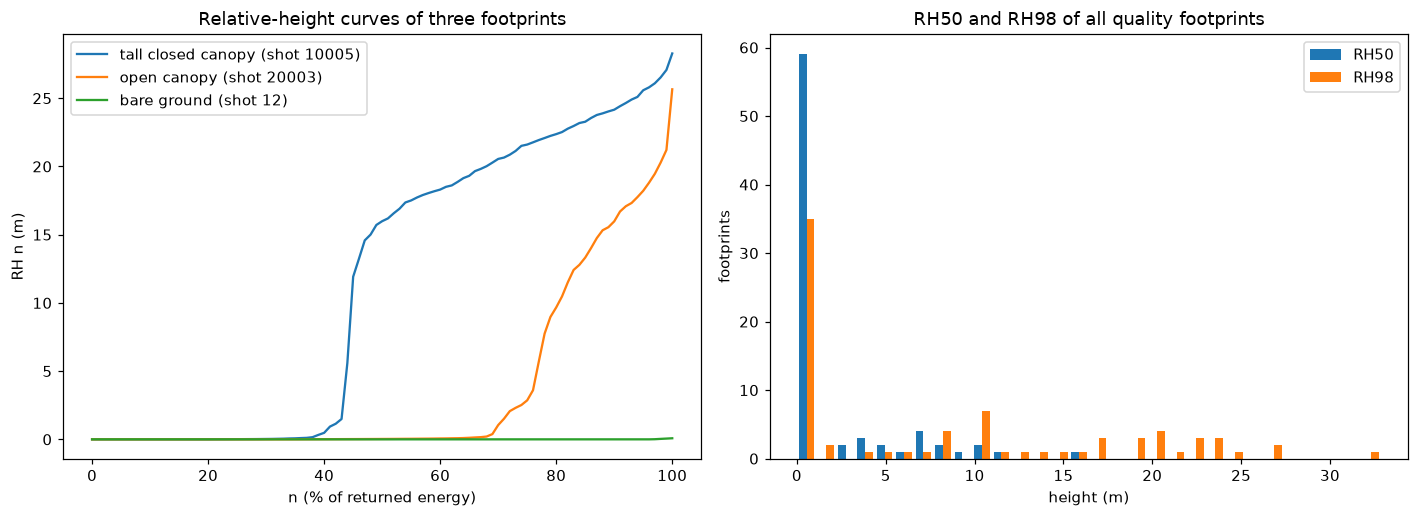

In [6]:
rh_cols = [f"rh{p}" for p in range(101)]  # RH0 to RH100
# three contrasting footprints
picks = {"tall closed canopy": gedi.loc[(gedi.rh50 > 15), "rh98"].idxmax() if (gedi.rh50 > 15).any() else gedi.rh98.idxmax(),
         "open canopy": (gedi.rh98.where(gedi.rh50 < 1) - 20).abs().idxmin(),  # tall top but most energy near ground
         "bare ground": gedi.rh98.idxmin()}  # lowest canopy
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))  # two panels
for name, i in picks.items():  # each example footprint
    axes[0].plot(range(101), gedi.loc[i, rh_cols].astype(float), label=f"{name} (shot {gedi.loc[i, 'shot_number']})")  # RH curve
# axis labels and title
axes[0].set(xlabel="n (% of returned energy)", ylabel="RH n (m)", title="Relative-height curves of three footprints")
axes[0].legend()  # legend
axes[1].hist([gedi.rh50, gedi.rh98], bins=30, label=["RH50", "RH98"])  # distributions over all footprints
# axis labels and title
axes[1].set(xlabel="height (m)", ylabel="footprints", title="RH50 and RH98 of all quality footprints"); axes[1].legend()
plt.tight_layout(); plt.show()  # draw

## GEDI heights versus airborne LiDAR

For each quality footprint, the ALS returns within 12.5 m of the **reported** position give the airborne RH98. The scatter plot compares it with GEDI RH98, which came from the true (shifted) position.


78 footprints | bias -0.66 m | RMSE 3.14 m | r = 0.95


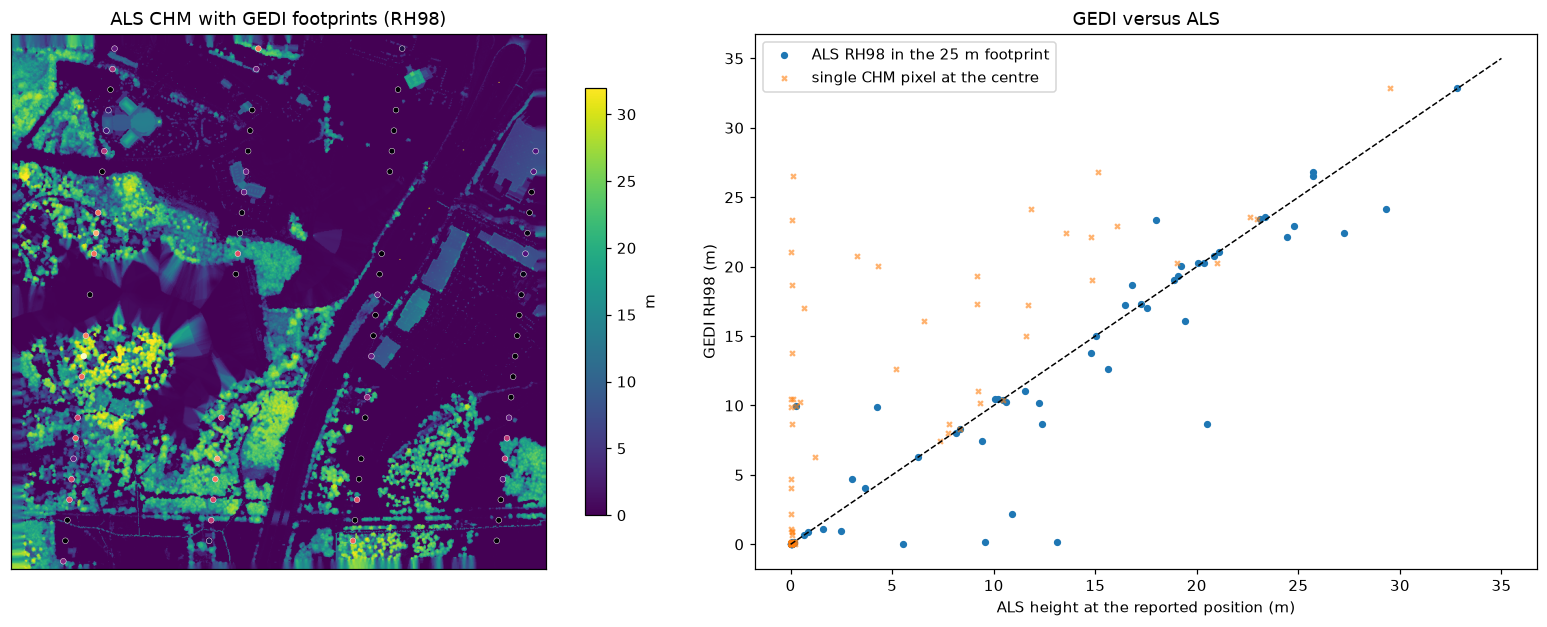

In [7]:
gutm = gedi.to_crs(32615)  # footprints in UTM
gutm["als_rh98"] = [r[98] if (r := footprint_rh(p.x, p.y)) is not None else np.nan for p in gutm.geometry]  # ALS at reported position
# one 2 m CHM pixel at the centre
gutm["chm_pixel"] = chm2.sel(x=xr.DataArray(gutm.geometry.x.values), y=xr.DataArray(gutm.geometry.y.values),
                             method="nearest").values  # one 2 m CHM pixel at the centre
d = gutm.dropna(subset=["als_rh98"])  # footprints with ALS data
err = d.rh98 - d.als_rh98  # GEDI minus ALS
# summary line
print(f"{len(d)} footprints | bias {err.mean():+.2f} m | RMSE {np.sqrt((err ** 2).mean()):.2f} m | "
      f"r = {np.corrcoef(d.rh98, d.als_rh98)[0, 1]:.2f}")  # agreement

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))  # two panels
rs.viz.plot_raster(chm2, ax=axes[0], cmap="viridis", vmin=0, vmax=32, title="ALS CHM with GEDI footprints (RH98)")  # CHM
gutm.plot(ax=axes[0], column="rh98", cmap="magma", markersize=14, edgecolor="white", linewidth=0.3)  # footprints
axes[0].set_xticks([]); axes[0].set_yticks([])  # no ticks
axes[1].scatter(d.als_rh98, d.rh98, s=14, label="ALS RH98 in the 25 m footprint")  # footprint-based comparison
axes[1].scatter(d.chm_pixel, d.rh98, s=10, marker="x", alpha=0.6, label="single CHM pixel at the centre")  # pixel-based
axes[1].plot([0, 35], [0, 35], "k--", lw=1)  # 1:1 line
# axis labels and title
axes[1].set(xlabel="ALS height at the reported position (m)", ylabel="GEDI RH98 (m)", title="GEDI versus ALS")
axes[1].legend(); plt.tight_layout(); plt.show()  # draw

The correlation is high (r about 0.95), because tall forest and clearings are large compared with a footprint. Still, individual footprints differ from the ALS value at their reported position by about 3 m RMSE, although both come from exactly the same points: the ~10 m geolocation error means each GEDI footprint sampled a partly different patch of forest. The crosses compare GEDI with a single 2 m CHM pixel at the footprint centre, which covers 4 m² of a 490 m² footprint and scatters more widely.


## How geolocation error and footprint size matter

The experiment below uses only the ALS data. For every footprint position it computes the ALS RH98 at the reported position and at positions shifted by random errors of 0, 5, 10, 15 and 20 m (standard deviation per axis), for footprint diameters of 10, 25 and 50 m. The RMSE between shifted and unshifted RH98 shows how much scatter geolocation error alone produces, and how a larger footprint (which averages more of the canopy) dampens it.


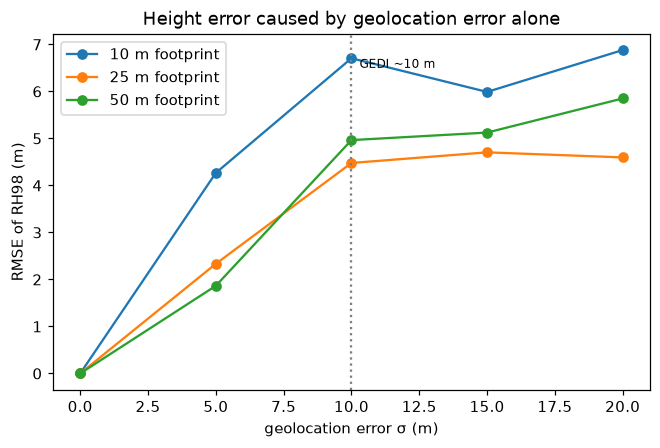

footprint diameter (m),10,25,50
geolocation error σ (m),,,
0,0.00,0.00,0.00
5,4.27,2.33,1.87
10,6.71,4.48,4.96
15,5.99,4.70,5.12
20,6.88,4.60,5.85


In [8]:
rng = np.random.default_rng(3)  # reproducible shifts
pos = np.c_[gutm.geometry.x, gutm.geometry.y]  # reported positions
rows = []  # one row per setting
for diam in (10, 25, 50):  # footprint diameters (m)
    ref = np.array([r[98] if (r := footprint_rh(x, y, diam / 2, 5)) is not None else np.nan for x, y in pos])  # unshifted
    for sigma in (0, 5, 10, 15, 20):  # geolocation error (m)
        shifted = pos + rng.normal(0, sigma, pos.shape)  # shifted positions
        val = np.array([r[98] if (r := footprint_rh(x, y, diam / 2, 5)) is not None else np.nan for x, y in shifted])  # RH98
        e = val - ref  # difference caused by the shift
        # result of this setting
        rows.append({"footprint diameter (m)": diam, "geolocation error σ (m)": sigma, "RMSE (m)": np.sqrt(np.nanmean(e ** 2))})
geo = pd.DataFrame(rows)  # results
fig, ax = plt.subplots(figsize=(7, 4.2))  # one panel
for diam, g_ in geo.groupby("footprint diameter (m)"):  # each footprint size
    ax.plot(g_["geolocation error σ (m)"], g_["RMSE (m)"], "o-", label=f"{diam} m footprint")  # RMSE curve
ax.axvline(10, ls=":", c="grey"); ax.text(10.3, ax.get_ylim()[1] * 0.9, "GEDI ~10 m", fontsize=8)  # GEDI's error
# axis labels and title
ax.set(xlabel="geolocation error σ (m)", ylabel="RMSE of RH98 (m)", title="Height error caused by geolocation error alone")
ax.legend(); plt.show()  # draw
geo.pivot(index="geolocation error σ (m)", columns="footprint diameter (m)", values="RMSE (m)").round(2)  # table

At GEDI's 10 m geolocation error, a 25 m footprint in this mixed forest changes its RH98 by about 4.5 m without any change in the forest. The error grows quickly up to about 10 m and then levels off: beyond that, the shifted footprint samples an essentially unrelated patch of forest. Small footprints are the most sensitive. A 50 m footprint helps only for small shifts here, because this forest varies at scales larger than 50 m (stands and clearings). This is why GEDI's calibration against ALS uses simulated waveforms over a small search grid of positions, and why individual footprints should not be compared with individual trees or CHM pixels.


## ICESat-2 ATL08 canopy and terrain heights

`rs.lidar.read_atl08` reads the 100 m land segments of each beam, converts fill values (3.4 × 10³⁸) to NaN and can keep only strong beams with `strong_only=True`, using the spacecraft orientation in `orbit_info/sc_orient`. The figure compares the segment canopy heights with the ALS CHM along the same track, and the segment terrain heights with the ALS DEM.


       h_canopy  h_te_best_fit  canopy_openness  night_flag
count     10.00          15.00             15.0        15.0
mean      20.45         107.34              3.0         1.0
min        6.20         104.36              3.0         1.0
max       28.63         112.40              3.0         1.0


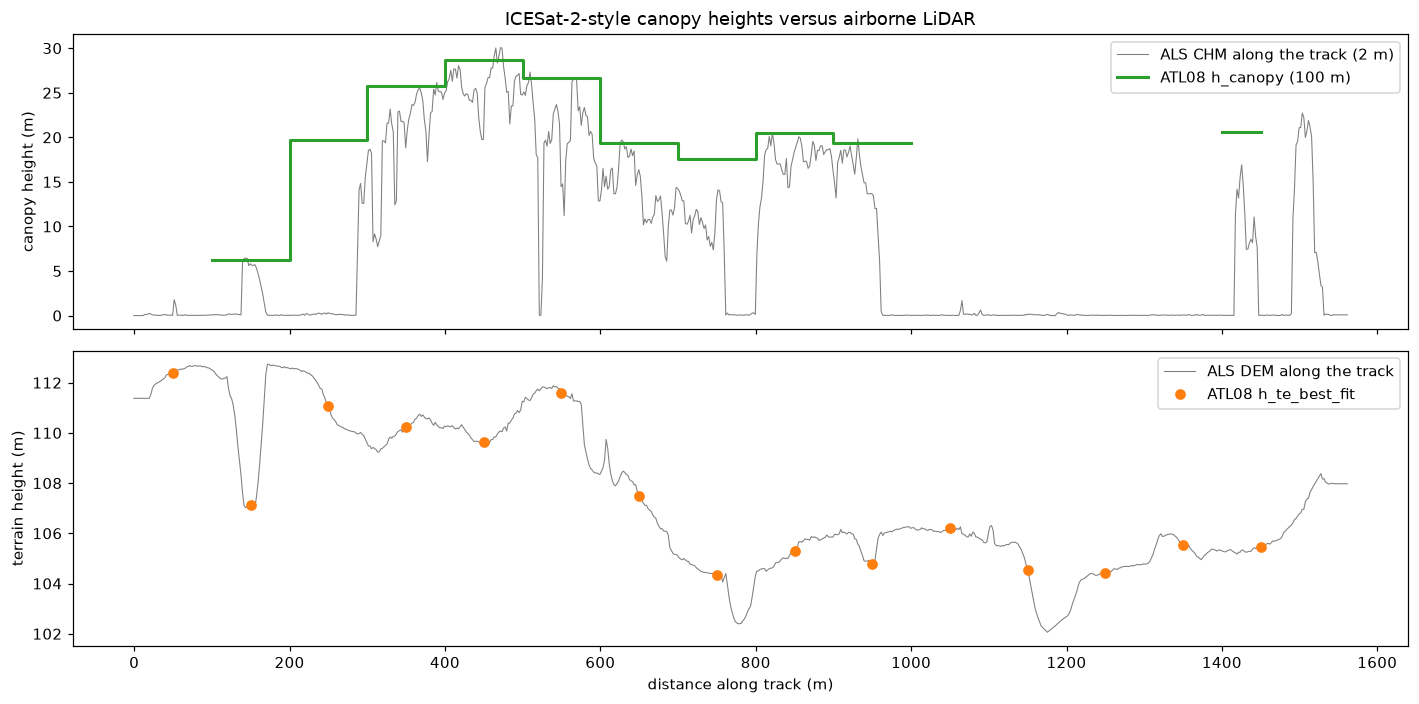

In [9]:
atl = rs.lidar.read_atl08(ATL08_FILE, strong_only=True).to_crs(32615)  # strong-beam segments in UTM
print(atl.drop(columns="geometry").describe().loc[["count", "mean", "min", "max"]].round(2))  # summary
xt = float(atl.geometry.x.mean())  # track x position
prof = chm2.sel(x=xt, method="nearest")  # CHM column under the track
dem_prof = dem2.sel(x=xt, method="nearest")  # DEM column under the track
y_start = float(atl.geometry.y.min()) - 50  # start of the track

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)  # two panels
axes[0].plot(prof.y - y_start, prof.values, color="grey", lw=0.7, label="ALS CHM along the track (2 m)")  # CHM profile
axes[0].step(atl.geometry.y - y_start, atl.h_canopy, where="mid", color="C2", lw=2, label="ATL08 h_canopy (100 m)")  # ATL08
# axis labels and title
axes[0].set(ylabel="canopy height (m)", title="ICESat-2-style canopy heights versus airborne LiDAR"); axes[0].legend()
axes[1].plot(dem_prof.y - y_start, dem_prof.values, color="grey", lw=0.7, label="ALS DEM along the track")  # DEM profile
axes[1].plot(atl.geometry.y - y_start, atl.h_te_best_fit, "o", color="C1", label="ATL08 h_te_best_fit")  # terrain heights
# axis labels and title
axes[1].set(xlabel="distance along track (m)", ylabel="terrain height (m)"); axes[1].legend()
plt.tight_layout(); plt.show()  # draw

The 100 m segments follow the large-scale pattern of the canopy, tall forest versus clearings, but smooth out every crown and gap within a segment. Segments over water or open ground have no canopy photons and carry the fill value (shown as gaps). Real ATL08 terrain heights are relative to the WGS 84 ellipsoid; here they were simulated from the orthometric ALS DEM, so the two agree by construction.


## From footprints to a raster

`rs.lidar.footprints_to_raster` grids footprint values onto any raster template, averaging the footprints in each cell. On a 200 m grid the sparse GEDI tracks fill only some cells; the ALS mean p95 per 200 m cell from `rs.lidar.grid_metrics` gives the wall-to-wall reference. Producing a continuous map from footprints requires a model that relates them to wall-to-wall predictors (optical and radar images), as in GEDI's L4B product and in the image fusion chapter.


cells with at least one footprint: 30 of 72 | mean footprints per sampled cell 2.6 | r(GEDI RH98, ALS p95) = 0.78


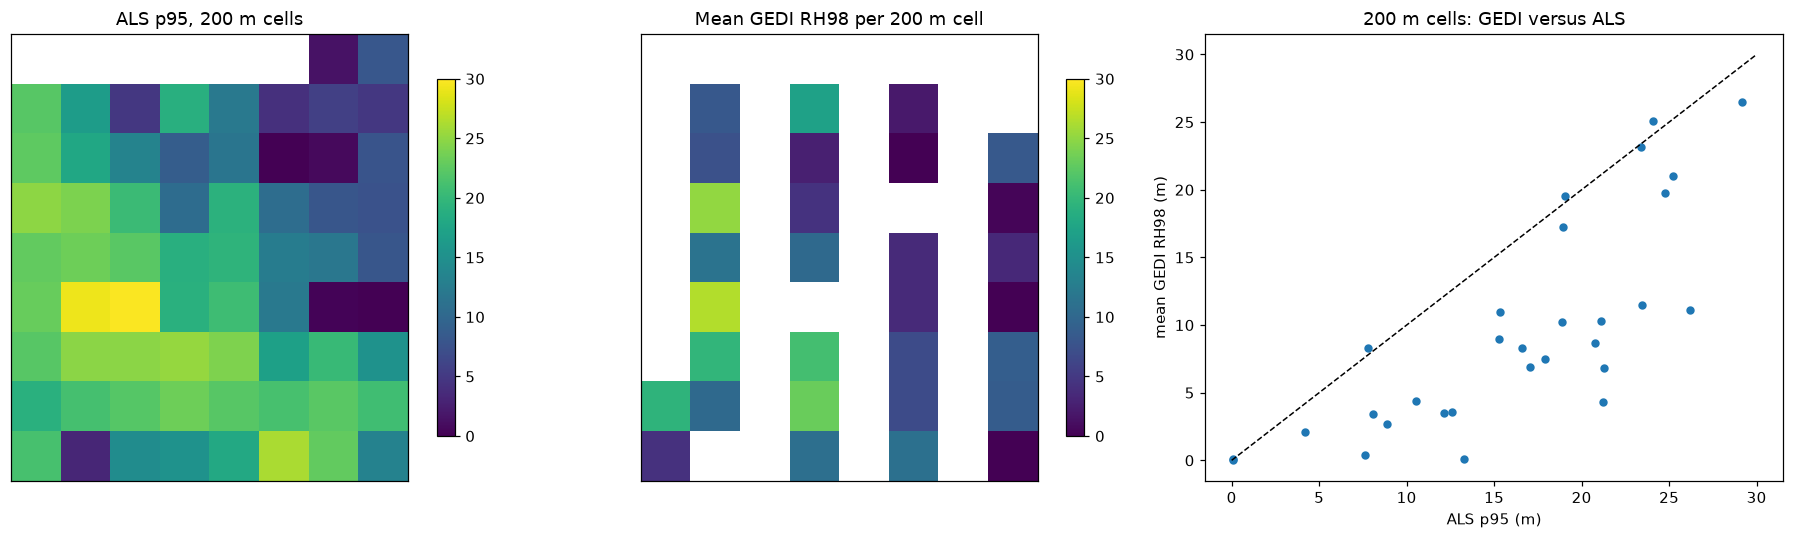

In [10]:
grid200 = rs.lidar.grid_metrics(pcn, res=200.0, metrics=("p95", "hmean"))  # ALS metrics on a 200 m grid
g_rh98 = rs.lidar.footprints_to_raster(gutm, "rh98", grid200["p95"], stat="mean")  # GEDI RH98 on the same grid
g_n = rs.lidar.footprints_to_raster(gutm, "rh98", grid200["p95"], stat="count")  # footprints per cell
both = np.isfinite(g_rh98.values) & np.isfinite(grid200["p95"].values)  # cells with both
# summary line
print(f"cells with at least one footprint: {int(np.isfinite(g_rh98.values).sum())} of {g_rh98.size} | "
      f"mean footprints per sampled cell {float(np.nanmean(g_n.values)):.1f} | "
      f"r(GEDI RH98, ALS p95) = {np.corrcoef(g_rh98.values[both], grid200['p95'].values[both])[0, 1]:.2f}")  # agreement

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
rs.viz.plot_raster(grid200["p95"], ax=axes[0], cmap="viridis", vmin=0, vmax=30, title="ALS p95, 200 m cells")  # reference
rs.viz.plot_raster(g_rh98, ax=axes[1], cmap="viridis", vmin=0, vmax=30, title="Mean GEDI RH98 per 200 m cell")  # gridded GEDI
for a in axes[:2]: a.set_xticks([]); a.set_yticks([])  # no ticks
axes[2].scatter(grid200["p95"].values[both], g_rh98.values[both], s=20)  # cell-level comparison
axes[2].plot([0, 30], [0, 30], "k--", lw=1)  # 1:1 line
# axis labels and title
axes[2].set(xlabel="ALS p95 (m)", ylabel="mean GEDI RH98 (m)", title="200 m cells: GEDI versus ALS")
plt.tight_layout(); plt.show()  # draw

Gridding reveals the other limit of spaceborne sampling. Only part of the 200 m cells contain a footprint, and those hold on average fewer than three, which together cover about 3 % of a 4 ha cell. Their mean is therefore a noisy estimate of the cell's canopy (r about 0.78 with the ALS p95), worse than the footprint-level agreement: at this scale sparse sampling, not measurement error, dominates. RH98 is a top-of-canopy measure and sits above the ALS p95 of all returns, which includes the lower layers. Wall-to-wall maps therefore combine the footprints with image predictors rather than relying on footprint averages alone.


## Exporting the products


In [11]:
# GEDI footprints with ALS values
gutm.drop(columns=[c for c in gutm.columns if c.startswith("rh") and c not in ("rh25", "rh50", "rh75", "rh95", "rh98", "rh100")]
          ).to_file(OUT / "spaceborne_madison.gpkg", layer="gedi_l2a", driver="GPKG")  # GEDI footprints with ALS values
atl.to_file(OUT / "spaceborne_madison.gpkg", layer="atl08", driver="GPKG")  # ATL08 segments
rs.write(g_rh98.astype("float32"), OUT / "gedi_rh98_200m.tif")  # gridded GEDI RH98
for p in (OUT / "spaceborne_madison.gpkg", OUT / "gedi_rh98_200m.tif"):  # what was written
    print(f"{p.name:28s} {p.stat().st_size / 1e3:8.0f} kB")  # name and size

spaceborne_madison.gpkg           139 kB
gedi_rh98_200m.tif                  2 kB


## Summary and exercises

**Key points**

- GEDI records full waveforms in 25 m footprints along eight tracks between 51.6° N and S; L2A gives relative heights (RH98 ≈ canopy top), L2B canopy cover and profiles, L4A and L4B biomass.
- ICESat-2 counts single green photons in 11 to 13 m footprints along six beams; ATL08 summarises them as terrain and canopy heights in 100 m segments.
- Always filter: GEDI `quality_flag`, `degrade_flag` and sensitivity (≥ 0.9, higher in dense forest), full-power beams and night shots; ICESat-2 strong beams and night data.
- Geolocation error (about 10 m for GEDI) alone causes metres of height scatter in heterogeneous forest; compare footprints with ALS metrics over the same footprint area, not single pixels. Gridded footprint means are limited by how few footprints fall in each cell.
- Spaceborne heights are relative to the WGS 84 ellipsoid; check vertical datums before comparing ground elevations with national LiDAR.
- Footprints are samples; wall-to-wall maps need gridding plus models with image predictors.

**`geolattice.rsense` functions used:** `rs.lidar.read_las`, `rs.lidar.dem`, `rs.lidar.chm`, `rs.lidar.normalize_heights`, `rs.lidar.read_gedi_l2a`, `rs.lidar.read_atl08`, `rs.lidar.grid_metrics`, `rs.lidar.footprints_to_raster`, `rs.write`, `rs.viz.plot_raster`; for real data `rs.lidar.spaceborne.search`, `rs.lidar.read_gedi_l2b` and `rs.lidar.read_gedi_l4a`.

**Exercises**

1. Read the GEDI file with `min_sensitivity` of 0.95 and 0.98. How many footprints remain on each beam?
2. Repeat the geolocation experiment with RH50 instead of RH98. Is the middle of the canopy more or less sensitive to position errors?
3. For each footprint, search shifts of up to 20 m in 2 m steps for the ALS RH98 closest to the GEDI RH98. What is the distribution of the best shifts, and how does it compare with the simulated 10 m error?
4. Grid the GEDI footprints at 100 m, 200 m and 500 m. How does the correlation with ALS change?
5. With an Earthdata login, download one real GEDI L2A granule that crosses your study area and read it with `rs.lidar.read_gedi_l2a(path, bbox=...)`.
